# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Colab T4. Датасет [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) лицензия Creative Commons Attribution-ShareAlike 4.0 International License. Бонусы 6.2–6.5.

In [1]:
import subprocess
import sys

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'ultralytics==8.4.211', 'onnx>=1.16,<2', 'onnxruntime>=1.18'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageEnhance

import torch
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

from torchvision.datasets.utils import download_and_extract_archive

assert ultralytics.__version__ == '8.4.211'

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(dict(ultralytics=ultralytics.__version__, torch=torch.__version__, device=DEVICE_NAME))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{'ultralytics': '8.4.211', 'torch': '2.14.1+cu130', 'device': 'Tesla T4'}


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 30
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    kw.setdefault('nms', False)
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, rect=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'
model_coco = YOLO(WEIGHTS)
weights_path = Path(model_coco.ckpt_path)


def sync_device(device):
    if isinstance(device, int) or str(device).startswith('cuda'):
        torch.cuda.synchronize()
    elif str(device) == 'mps':
        torch.mps.synchronize()


def latency_ms(model, image, device=DEVICE, repeats=20, **kwargs):
    args = dict(imgsz=IMGSZ, device=device, verbose=False, rect=False, conf=0.001, nms=False)
    args.update(kwargs)
    for _ in range(3):
        model.predict(image, **args)
    sync_device(device)
    start = time.perf_counter()
    for _ in range(repeats):
        model.predict(image, **args)
    sync_device(device)
    return (time.perf_counter() - start) * 1000 / repeats


MODEL_INFO = dict(
    ultralytics=ultralytics.__version__, weights=weights_path.name,
    sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
    size_mb=weights_path.stat().st_size / 1024**2,
    params=sum(p.numel() for p in model_coco.model.parameters()),
    n_classes_coco=len(model_coco.names),
)
dummy_image = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
MODEL_INFO['latency_ms'] = latency_ms(model_coco, dummy_image)
MODEL_INFO['latency_device'] = DEVICE_NAME

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.211',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 24.835034550000046,
 'latency_device': 'Tesla T4'}

**Ответ:** Взял маленькую yolo26n: обучающих фото всего 800, и хотелось обучить побыстрее. В выводе получилось 2 572 280 параметров и 24.84 мс на картинку. По таблице из вопроса версия s точнее на 7.7 п. на COCO, но у неё больше параметров и она медленнее(9.5м параметров, медленнее почти в 2 раза 39 vs 87 мс), поэтому здесь выбрал n. У кода и весов лицензия AGPL-3.0, при распространении надо сохранять лицензию и давать пользователям исходники, в том числе для изменённой программы

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    layers = det_model.model
    n_backbone = len(det_model.yaml['backbone'])
    return dict(
        backbone=sum(p.numel() for layer in layers[:n_backbone] for p in layer.parameters()),
        neck=sum(p.numel() for layer in layers[n_backbone:-1] for p in layer.parameters()),
        head=sum(p.numel() for p in layers[-1].parameters()),
    )


def head_inputs_and_output(det_model, imgsz=640):
    feat_shapes = []

    def hook(module, args):
        feat_shapes.extend(tuple(x.shape) for x in args[0])

    handle = det_model.model[-1].register_forward_pre_hook(hook)
    was_training = det_model.training
    p = next(det_model.parameters())
    try:
        det_model.eval()
        with torch.inference_mode():
            out = det_model(torch.zeros(1, 3, imgsz, imgsz, device=p.device, dtype=p.dtype))
    finally:
        handle.remove()
        det_model.train(was_training)
    return feat_shapes, out


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print(shapes(out))

[(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:** Backbone находит признаки на картинке, neck объединяет их с разных масштабов, а head выдаёт рамки и классы. В выводе перед Detect видны три карты 80×80, 40×40 и 20×20 что дают  $80^2+40^2+20^2=8400$. Готовых шаблонов рамок нет, поэтому модель называют anchor-free. При обучении one2many связывает один объект с несколькими предсказаниями, а one2one с одним, что позволяет работать без NMS. По числу параметров backbone занимает 53%, neck 35%, head 12%.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
PET_ROOT = DATA_ROOT / 'oxford_pets'
PET_ROOT.mkdir(parents=True, exist_ok=True)
BASE_URL = 'https://www.robots.ox.ac.uk/~vgg/data/pets/data/'
for filename, md5, folder in [
    ('images.tar.gz', '5c4f3ee8e5d25df40f4fd59a7f44e54c', 'images'),
    ('annotations.tar.gz', '95a8c909bbe2e81eed6a22bccdf3f68f', 'annotations'),
]:
    if not (PET_ROOT / folder).is_dir():
        download_and_extract_archive(BASE_URL + filename, str(PET_ROOT), md5=md5)

CLASSES = ['cat', 'dog']
DATASET_NAME = 'Oxford-IIIT Pet, head detection; https://www.robots.ox.ac.uk/~vgg/data/pets/; CC BY-SA 4.0'
by_class = {name: [] for name in CLASSES}
CLEANING = Counter()
for line in (PET_ROOT / 'annotations' / 'trainval.txt').read_text().splitlines():
    if not line.strip() or line.startswith('#'):
        continue
    image_id = line.split()[0]
    xml_path = PET_ROOT / 'annotations' / 'xmls' / f'{image_id}.xml'
    if not xml_path.exists():
        CLEANING['missing_xml'] += 1
        continue
    root = ET.parse(xml_path).getroot()
    image_path = PET_ROOT / 'images' / f'{image_id}.jpg'
    with Image.open(image_path) as image:
        width, height = image.size
    boxes, labels = [], []
    for obj in root.findall('object'):
        name = obj.findtext('name').strip().lower()
        coords = obj.find('bndbox')
        box = np.array([float(coords.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
        box[:2] -= 1
        clipped = np.clip(box, [0, 0, 0, 0], [width, height, width, height])
        CLEANING['clipped'] += int(not np.array_equal(box, clipped))
        if not np.isfinite(clipped).all() or (clipped[2:] <= clipped[:2]).any():
            CLEANING['removed'] += 1
            continue
        boxes.append(clipped)
        labels.append(CLASSES.index(name))
    if boxes:
        record = dict(image=image_path, width=width, height=height,
                      boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4),
                      labels=np.array(labels, dtype=np.int64))
        by_class[CLASSES[labels[0]]].append(record)

records = {'train': [], 'val': []}
rng = np.random.default_rng(SEED)
for name, recs in by_class.items():
    assert len(recs) >= 500, (name, len(recs))
    order = rng.permutation(len(recs))[:500]
    records['train'].extend(recs[i] for i in order[:400])
    records['val'].extend(recs[i] for i in order[400:])
assert not ({r['image'] for r in records['train']} & {r['image'] for r in records['val']})
print(dict(CLEANING))

100%|██████████| 792M/792M [00:37<00:00, 20.9MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.28MB/s]


{'clipped': 0, 'missing_xml': 9}


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 800, 'val': 200}

train {'images': 800, 'counts': {'cat': 401, 'dog': 400}, 'objects_per_image': np.float64(1.00125)}
val {'images': 200, 'counts': {'cat': 100, 'dog': 100}, 'objects_per_image': np.float64(1.0)}


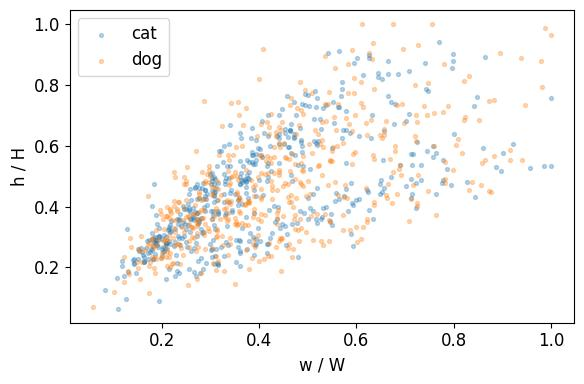

In [11]:
DATA_STATS = {}
for split, recs in records.items():
    counts = np.bincount(np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES))
    DATA_STATS[split] = dict(images=len(recs), counts=dict(zip(CLASSES, counts.tolist())),
                             objects_per_image=sum(counts) / len(recs))
    print(split, DATA_STATS[split])
plt.figure(figsize=(6, 4))
for c, name in enumerate(CLASSES):
    sizes = np.concatenate([(r['boxes'][r['labels'] == c, 2:] - r['boxes'][r['labels'] == c, :2])
                            / [r['width'], r['height']] for recs in records.values() for r in recs])
    plt.scatter(sizes[:, 0], sizes[:, 1], s=8, alpha=0.3, label=name)
plt.xlabel('w / W')
plt.ylabel('h / H')
plt.legend()
plt.tight_layout()
plt.show()

**Ответ:** Использовал Oxford-IIIT Pet с лицензией Creative Commons Attribution-ShareAlike 4.0 International License. случайно выбрал по 500 фотографий кошек и собак, из них по 400 взял в train и по 100 в val. Получилось 800/200 фотографий и 801/200 объектов, то есть почти везде одна голова, но размеры разные. Классов примерно поровну, при чтении пропущены 9 фото без XML, обрезать или удалять рамки не пришлось

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)
    lines = []
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        cx, cy = (x1 + x2) / (2 * width), (y1 + y2) / (2 * height)
        w, h = (x2 - x1) / width, (y2 - y1) / height
        lines.append(f'{label} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}')
    return '\n'.join(lines)


def from_yolo(text, width, height):
    boxes, labels = [], []
    for line in text.splitlines():
        if not line.strip():
            continue
        label, cx, cy, w, h = map(float, line.split())
        boxes.append([(cx - w / 2) * width, (cy - h / 2) * height,
                      (cx + w / 2) * width, (cy + h / 2) * height])
        labels.append(int(label))
    return np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(labels, dtype=np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    for r in recs:
        image_path = Path(r['image'])
        shutil.copy2(image_path, image_dir / image_path.name)
        text = to_yolo(r['boxes'], r['labels'], r['width'], r['height'])
        (label_dir / f'{image_path.stem}.txt').write_text(text)


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)

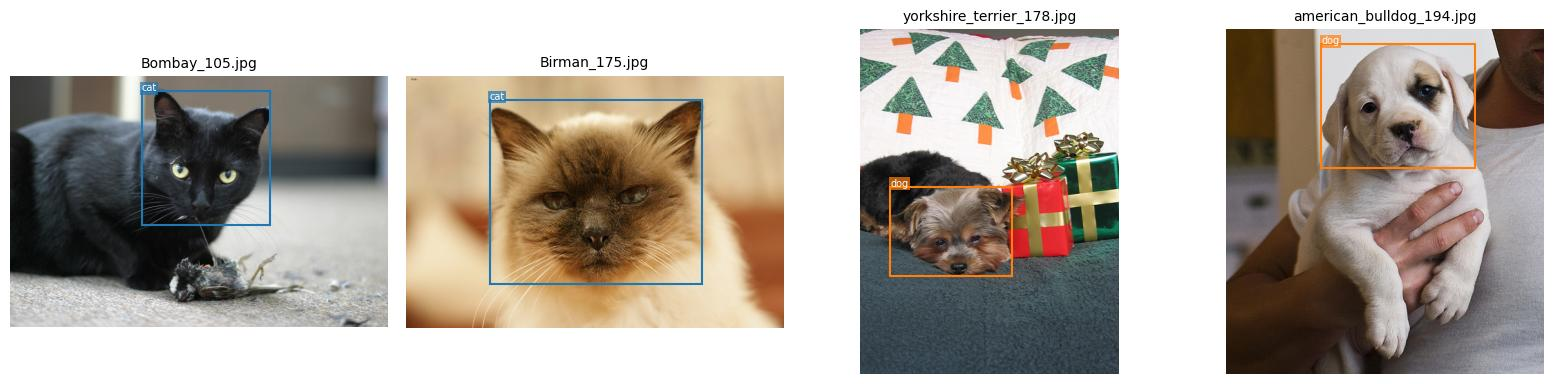

In [15]:
for split, recs in splits.items():
    for r in recs:
        text = (YOLO_ROOT / 'labels' / split / f'{Path(r["image"]).stem}.txt').read_text()
        boxes, labels = from_yolo(text, r['width'], r['height'])
        assert np.array_equal(labels, r['labels'])
        assert np.allclose(boxes, r['boxes'], atol=1e-5 * max(r['width'], r['height']))
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, r in zip(axes, records['val'][:2] + records['val'][-2:]):
    text = (YOLO_ROOT / 'labels' / 'val' / f'{Path(r["image"]).stem}.txt').read_text()
    boxes, labels = from_yolo(text, r['width'], r['height'])
    with Image.open(r['image']) as image:
        draw_boxes(ax, image.convert('RGB'), boxes, labels, CLASSES, title=Path(r['image']).name)
plt.tight_layout()
plt.show()

**Ответ:** Тест проверяет, что после перевода рамок из пиксельных координат в yolo формат и обратно получаются те же координаты с небольшой погрешностью

Он не проверяет, правильно ли размечено изображение и подходит ли ему эта разметка. Ещё тест может пропустить ошибки, которые отменяют друг друга, если обе функции одинаково путают ширину и высоту

На картинке можно заметить, что рамки съехали, растянулись, обрезались или вообще не попадают на объект. Также будет видно, если разметка относится к другой фотографии или рамка обводит всё животное вместо головы

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [16]:
coco_preds_raw = predict_records(model_coco, records[FINAL_SPLIT])
coco_to_pet = {i: CLASSES.index(name) for i, name in model_coco.names.items() if name in CLASSES}
coco_preds = []
for p in coco_preds_raw:
    keep = np.array([int(c) in coco_to_pet for c in p['labels']], dtype=bool)
    coco_preds.append(dict(boxes=p['boxes'][keep], scores=p['scores'][keep],
                           labels=np.array([coco_to_pet[int(c)] for c in p['labels'][keep]], dtype=np.int64)))
coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
print(dict(map50=coco_map50, ap50=dict(zip(CLASSES, coco_aps))))

{'map50': 0.06664329101813993, 'ap50': {'cat': 0.05266412219344212, 'dog': 0.08062245984283772}}


In [17]:
def heuristic_detect(image_path):
    with Image.open(image_path) as image:
        width, height = image.size
    return dict(boxes=HEURISTIC_BOXES * [width, height, width, height],
                labels=np.arange(len(CLASSES), dtype=np.int64), scores=np.full(len(CLASSES), 0.5))

In [18]:
HEURISTIC_BOXES = []
for c in range(len(CLASSES)):
    boxes = np.concatenate([r['boxes'][r['labels'] == c] / [r['width'], r['height'], r['width'], r['height']]
                            for r in train_recs])
    HEURISTIC_BOXES.append(np.median(boxes, axis=0))
HEURISTIC_BOXES = np.array(HEURISTIC_BOXES, dtype=np.float32)

In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
BASELINE

{'split': 'val',
 'coco_map50': 0.06664329101813993,
 'heuristic_map50': 0.0889915401374761,
 'heuristic_ap50_per_class': {'cat': 0.14078920272393178,
  'dog': 0.03719387755102041}}

**Ответ:** У COCO-модели mAP50=0.0666. Кошек и собак она знает, но обычно обводит животное целиком, а у нас размечены только головы. Поэтому модель может правильно определить класс, но её рамка плохо совпадёт с разметкой IoU

Эвристика лучше показала себя на кошка AP50=0.1408, у собак только 0.0372. Но оба результата низкие. Она не смотрит на содержимое фотографии, а просто ставит типичную рамку каждого класса, посчитанную по train. Попадание получается только тогда, когда положение и размер головы подходят под эту рамку. Если животное находится в другом месте или снято с другого расстояния, эвристика ошибается

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer='AdamW',
                  lr0=0.001, lrf=0.1, warmup_epochs=1,
                  patience=10, seed=SEED, val=True, plots=True,
                  hsv_s=0.4, hsv_v=0.3, degrees=10,
                  scale=0.3, fliplr=0.5, flipud=0.0, mosaic=0.0, mixup=0.0,
                  amp=False, nms=False)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(dict(train_sec=RUN_TIMES['train'], device=DEVICE_NAME))

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=finetune, nbs=64, nms=False, opset=None, optimize=False, optimizer=Ad

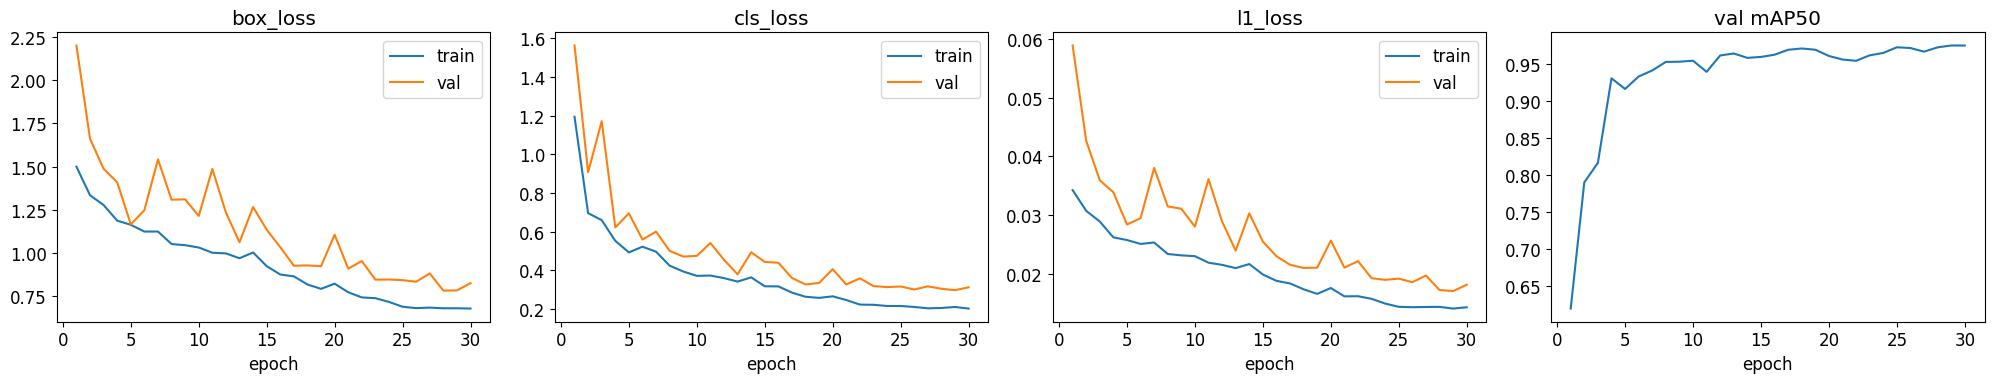

{'epochs': 30, 'best_epoch': 28}


In [22]:
curves = read_results(run_dir)
loss_names = [k for k in curves if k.startswith('train/') and k.endswith('_loss')]
fig, axes = plt.subplots(1, len(loss_names) + 1, figsize=(5 * (len(loss_names) + 1), 4))
for ax, key in zip(axes, loss_names):
    val_key = key.replace('train/', 'val/')
    ax.plot(curves['epoch'], curves[key], label='train')
    ax.plot(curves['epoch'], curves[val_key], label='val')
    ax.set(title=key.split('/')[-1], xlabel='epoch')
    ax.legend()
axes[-1].plot(curves['epoch'], curves['metrics/mAP50(B)'])
axes[-1].set(title='val mAP50', xlabel='epoch')
plt.tight_layout()
plt.show()
best_epoch = int(np.argmax(curves['metrics/mAP50-95(B)']))
print(dict(epochs=len(curves['epoch']), best_epoch=int(curves['epoch'][best_epoch])))

**Ответ:** Размер 640 оставил, чтобы не терять небольшие головы, а batch=16 поместился на T4. Для дообучения взял AdamW с lr=0.001, warmup=1 и остановкой после 10 эпох без улучшения. из аугментаций использовал небольшие повороты, изменения цвета и отражения по горизонтали. По графикам train и val loss в целом снижаются, сильного переобучения не видно, эпох хватило т.к в конце качество уже почти не растёт

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')
best_params = sum(p.numel() for p in best.model.parameters())


def val_metrics(model, split, name, **kw):
    args = dict(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, rect=False, nms=False)
    args.update(kw)
    return model.val(**args)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3311.8±882.2 MB/s, size: 120.7 KB)
val: Scanning /content/data/yolo/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 76.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.9it/s 2.7s
                   all        200        200      0.956      0.968      0.975      0.759
Speed: 2.2ms preprocess, 4.0ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /content/runs_hw2/final_val
{'cat': {'precision': 0.9800123987195857, 'recall': 0.9806261353390782, 'map50': 0.9844989498949894, 'map50_95': 0.8284097552068911}, 'dog': {'precision': 0.9317169500410628, 'recall': 0.9551689673305794, 'map50': 0.9654411422318724, 'map50_95': 0.6889881649840566}}


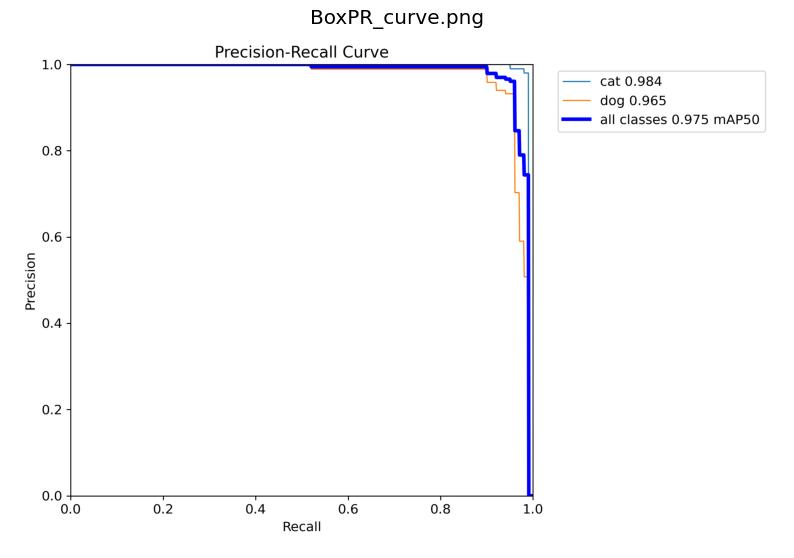

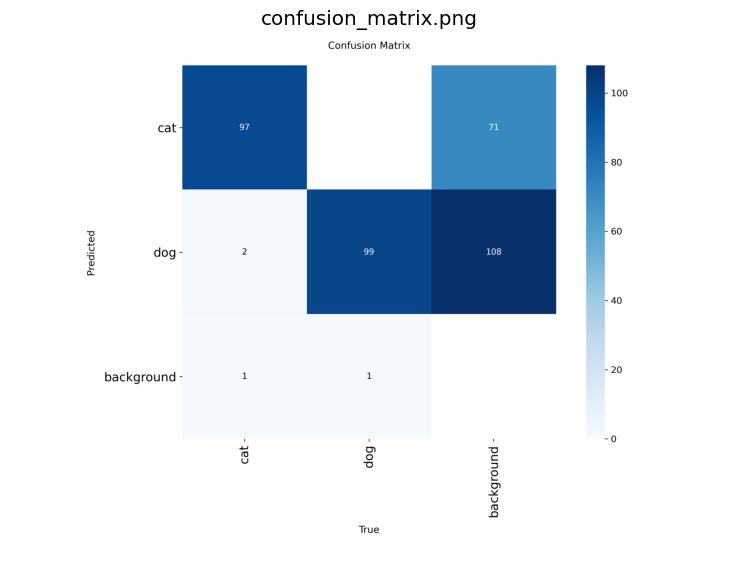

In [24]:
def pack_metrics(result):
    keys = ('precision', 'recall', 'map50', 'map50_95')
    per_class = {name: dict.fromkeys(keys, 0.0) for name in CLASSES}
    for i, c in enumerate(result.box.ap_class_index):
        per_class[CLASSES[c]] = dict(zip(keys, map(float, result.box.class_result(i))))
    return dict(zip(keys, map(float, result.box.mean_results())), per_class=per_class)


result = val_metrics(best, 'val', 'final_val', conf=0.001, iou=0.7, plots=True)
FINAL = dict(split=FINAL_SPLIT, **pack_metrics(result))
final_preds = predict_records(best, records[FINAL_SPLIT], iou=0.7)
FINAL['custom_map50'], custom_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
print(FINAL['per_class'])
for filename in ['BoxPR_curve.png', 'confusion_matrix.png']:
    plot_path = Path(result.save_dir) / filename
    if plot_path.exists():
        plt.figure(figsize=(10, 7))
        plt.imshow(plt.imread(plot_path))
        plt.axis('off')
        plt.title(filename)
        plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'split': 'val',
 'precision': 0.9559,
 'recall': 0.9679,
 'map50': 0.975,
 'map50_95': 0.7587,
 'custom_map50': 0.9808}

**Ответ:** Хуже получились собаки AP50–95 у них 0.6890, а у кошек 0.8284. В val по 100 объектов каждого класса, поэтому дело не в количестве примеров. Думаю, модели сложнее точно обвести разные формы голов и позы собак

В confusion matrix строки показывают предсказанный класс, а столбцы настоящий. На диагонали находятся правильные ответы, вне неё ошибки. Строка background означает пропущенные объекты, а столбец background означает лишние рамки. Матрица построена при conf=0.001  поэтому в неё попало много слабых предсказаний

mAP50 получился 0.9750, а mAP50–95 0.7587, потому что требования к рамкам там строже. Для mAP50 достаточно IoU от 0.5, а во втором случае результат усредняется по порогам от 0.5 до 0.95. Модель хорошо находит головы, но не всегда обводит их достаточно точно

Свой mAP50 получился 0.9808, у ltralytics 0.9750, то есть результаты близкие.
 Результаты отличаются т.к есть небольшие отличия в сопостовлении рамок, способе подсчета

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    left = np.maximum(a[:, None, :2], b[None, :, :2])
    right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.maximum(right - left, 0).prod(axis=2)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    gt_labels = np.asarray(gt['labels'])
    found = np.zeros(len(gt_labels), dtype=bool)
    linked = np.zeros(len(gt_labels), dtype=bool)
    cats = ['background'] * len(pred['scores'])
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = gt_labels == pred['labels'][i]
        candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_hit))
        category = 'tp'
        if not len(candidates):
            candidates = np.flatnonzero(~same & (ious[i] >= iou_hit))
            category = 'class'
        if not len(candidates):
            candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_loc) & (ious[i] < iou_hit))
            category = 'localization'
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            cats[i] = category
            linked[j] = True
            if category == 'tp':
                found[j] = True
    return cats, np.flatnonzero(~linked).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


{'tp': 194, 'class': 2, 'localization': 3, 'background': 6, 'missed': 3}
{'tp': 0.9327, 'class': 0.0096, 'localization': 0.0144, 'background': 0.0288, 'missed': 0.0144}
{'cat': {'tp': 98, 'class': 0, 'localization': 1, 'background': 1, 'missed': 1}, 'dog': {'tp': 96, 'class': 2, 'localization': 2, 'background': 5, 'missed': 2}}


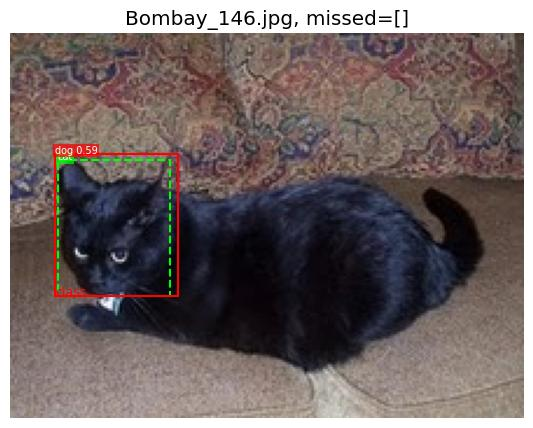

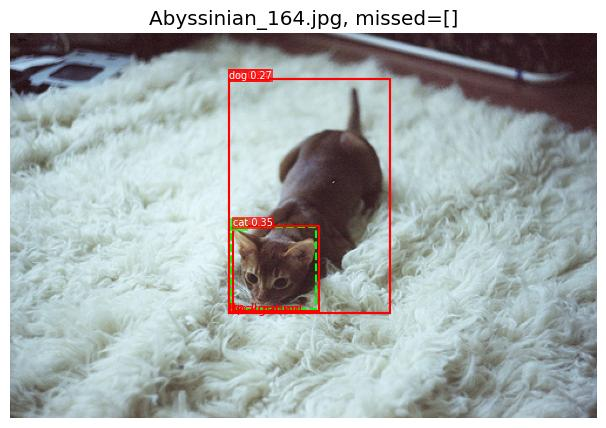

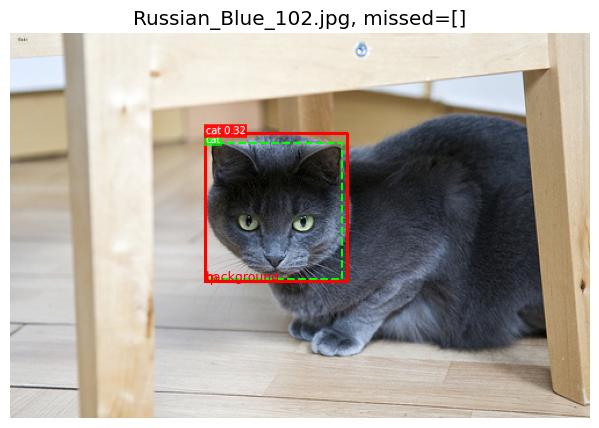

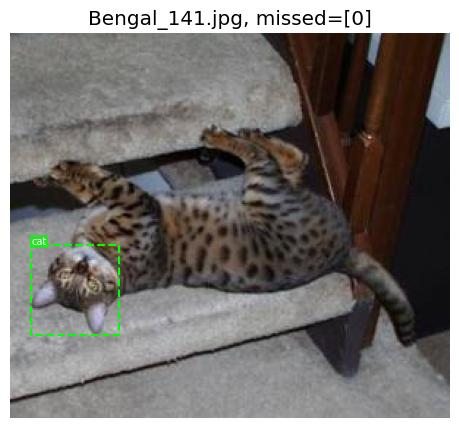

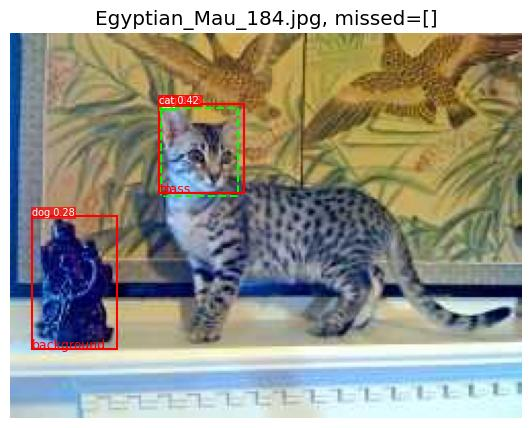

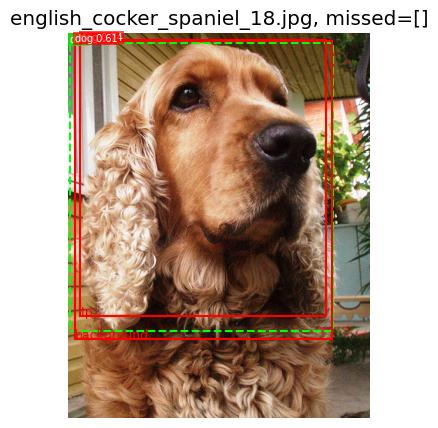

In [28]:
val_preds = [{k: v[p['scores'] >= CONF_ERRORS] for k, v in p.items()} for p in final_preds]
ERRORS = Counter({kind: 0 for kind in ERROR_TYPES})
ERRORS_BY_CLASS = {name: Counter({kind: 0 for kind in ERROR_TYPES}) for name in CLASSES}
error_details = []
for r, p in zip(records['val'], val_preds):
    cats, missed = categorize_predictions(p, r)
    ERRORS.update(cats)
    ERRORS['missed'] += len(missed)
    for c, category in zip(p['labels'], cats):
        ERRORS_BY_CLASS[CLASSES[c]][category] += 1
    for j in missed:
        ERRORS_BY_CLASS[CLASSES[r['labels'][j]]]['missed'] += 1
    error_details.append((cats, missed))
ERRORS = dict(ERRORS)
print(ERRORS)
print({k: round(v / max(sum(ERRORS.values()), 1), 4) for k, v in ERRORS.items()})
print({name: dict(counts) for name, counts in ERRORS_BY_CLASS.items()})
chosen = []
for category in ERROR_TYPES[1:]:
    for i, (cats, missed) in enumerate(error_details):
        if i not in chosen and (category in cats or (category == 'missed' and missed)):
            chosen.append(i)
            break
for i, (cats, missed) in enumerate(error_details):
    if len(chosen) >= 6:
        break
    if i not in chosen and (any(c != 'tp' for c in cats) or missed):
        chosen.append(i)

for i in chosen:
    r, p = records['val'][i], val_preds[i]
    cats, missed = error_details[i]
    fig, ax = plt.subplots(figsize=(8, 5))
    with Image.open(r['image']) as image:
        draw_boxes(ax, image.convert('RGB'), r['boxes'], r['labels'], CLASSES, color='lime', linestyle='--')
    draw_boxes(ax, None, p['boxes'], p['labels'], CLASSES, scores=p['scores'], color='red')
    for box, category in zip(p['boxes'], cats):
        ax.text(box[0], box[3], category, color='red', fontsize=9)
    ax.set_title(f'{Path(r["image"]).name}, missed={missed}')
    plt.show()

**Ответ:** Главная категория ошибок - background, 6 случаев при conf=0.25. Это лишние рамки, а также дубли одной головы

На примерах модель иногда дважды обводит голову или ставит большую рамку вокруг всего животного. Разметка на этих фотографиях стоит вокруг голов и выглядит нормально, поэтому здесь проблема скорее в модели

Я бы попробовал ветку one2many с NMS и подобрал IoU, чтобы убрать дубли. Для слабых ложных срабатываний можно немного поднять conf. После этого проверил бы, уменьшилось ли число лишних рамок и не стало ли больше пропущенных голов

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
ablation_args = dict(TRAIN_ARGS, freeze=len(arch.yaml['backbone']))
model_ablation, RUN_TIMES['ablation'], ablation_dir = train_yolo('freeze_backbone', **ablation_args)
ablation_best = YOLO(ablation_dir / 'weights' / 'best.pt')
ablation_metrics = pack_metrics(val_metrics(ablation_best, 'val', 'ablation_val',
                                            conf=0.001))
ABLATION = dict(changed='freeze', split='val', values=[0, len(arch.yaml['backbone'])],
                base=dict(**FINAL, train_time_sec=RUN_TIMES['train']),
                frozen=dict(**ablation_metrics, train_time_sec=RUN_TIMES['ablation']))

print(ABLATION)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=freeze_backbone, nbs=64, nms=False, opset=None, optimize=False, optimiz

**Ответ:** После заморозки первых 11 слоёв backbone обучение ускорилось: 462.9 с вместо 641.3 с. Эти слои больше не обновляются, поэтому обучать нужно меньше параметров -> быстрее

По качеству получилось неоднозначно. mAP50 немного вырос, с 0.9750 до 0.9798, но mAP50–95 снизился с 0.7587 до 0.7386. То есть при более строгой проверке совпадения рамок результат стал хуже

Для этой работы я бы оставил полное дообучение. Экономия примерно трёх минут небольшая, а точность рамок важна. Заморозка была бы акуальна, если время ограничено

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** После дообучения YOLO получила mAP50=0.9750 и mAP50–95=0.7587. Это намного лучше coco модели с mAP50=0.0666 и простой эвристики с 0.0890. Собаки дались хуже кошек AP50–95 у них 0.6890 против 0.8284. Чаще всего модель выдавала лишние рамки, таких ошибок было 6 при conf=0.25. Заморозка backbone сократила обучение с 641.3 до 462.9 с, но снизила mAP50–95 до 0.7386, поэтому я оставил полное дообучение. Результат проверен только на 200 фотографиях val и одном seed, поэтому пока нельзя считать его устойчивым. Дальше я бы проверил модель на отдельном test и повторил обучение с дополнительными аугментациями, например с добавлением шума.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')

BONUS_RESULTS = {}

---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    raise NotImplementedError

**Ответ:**

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR

    rt = RTDETR('rtdetr-l.pt')
    rt.model.yaml['scale'] = 'l'
    rt_args = dict(TRAIN_ARGS, batch=4 if FAST_MODE else 8, deterministic=False)
    start = time.perf_counter()
    rt.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
             name='rtdetr', exist_ok=True, verbose=False, **rt_args)
    RUN_TIMES['rtdetr'] = time.perf_counter() - start
    rt_best = RTDETR(Path(rt.trainer.save_dir) / 'weights' / 'best.pt')
    rt_params = sum(p.numel() for p in rt_best.model.parameters())
    rt_metrics = pack_metrics(val_metrics(rt_best, 'val', 'rtdetr_val', conf=0.001, batch=rt_args['batch']))
    yolo_ms = latency_ms(best, dummy_image)
    rt_ms = latency_ms(rt_best, dummy_image)
    BONUS_RESULTS['6.2'] = dict(
        yolo=dict(**FINAL, params=best_params, latency_ms=yolo_ms, train_sec=RUN_TIMES['train']),
        rtdetr=dict(**rt_metrics, params=rt_params, latency_ms=rt_ms,
                    train_sec=RUN_TIMES['rtdetr'], batch=rt_args['batch']), device=DEVICE_NAME)
    print(BONUS_RESULTS['6.2'])
    del rt, rt_best
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=rtdetr, nbs=64, nms=False, opset=None, optimize=False, optimizer=Ada

**Ответ:** При наших настройках RT-DETR не дал выигрыша по качеству. У него mAP50=0.9332 и mAP50–95=0.5957, а у yolo 0.9750 и 0.7587. То есть более тяжёлая модель здесь не помогла.

По времени тоже получилось хуже, обучение заняло 80.6 минуты вместо 10.7, а обработка картинки на T4 42.45 мс вместо 14.24 мс.

В итоге получился только проигрыш при выборе RT-DETR, но rt-detr можно выбрать в случае, когда его работа на определенных данных качественнее и есть возможность пожертвовать скоростью

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [33]:
if '6.3' in BONUS_TASKS:
    import yaml

    DOMAIN = {}
    rng = np.random.default_rng(SEED)
    for corruption in ['dark', 'noise']:
        domain_root = DATA_ROOT / f'domain_{corruption}'
        shutil.rmtree(domain_root, ignore_errors=True)
        image_dir = domain_root / 'images' / 'val'
        label_dir = domain_root / 'labels' / 'val'
        image_dir.mkdir(parents=True)
        label_dir.mkdir(parents=True)
        for r in records['val']:
            with Image.open(r['image']) as image:
                image = image.convert('RGB')
                if corruption == 'dark':
                    image = ImageEnhance.Brightness(image).enhance(0.35)
                else:
                    pixels = np.asarray(image, dtype=np.float32)
                    image = Image.fromarray(np.clip(pixels + rng.normal(0, 25, pixels.shape), 0, 255).astype(np.uint8))
                image.save(image_dir / f'{Path(r["image"]).stem}.png')
            shutil.copy2(YOLO_ROOT / 'labels' / 'val' / f'{Path(r["image"]).stem}.txt', label_dir)
        domain_yaml = domain_root / 'data.yaml'
        domain_yaml.write_text(yaml.safe_dump(dict(path=str(domain_root.resolve()),
                                                  train='images/val', val='images/val', names=CLASSES)))
        result = val_metrics(best, 'val', f'domain_{corruption}', data=str(domain_yaml),
                             conf=0.001, plots=False)
        DOMAIN[corruption] = pack_metrics(result)
    BONUS_RESULTS['6.3'] = dict(clean=FINAL, distorted=DOMAIN)
    print(BONUS_RESULTS['6.3'])

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2574.8±505.7 MB/s, size: 263.7 KB)
val: Scanning /content/data/domain_dark/labels/val... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 1.6Kit/s 0.1s
val: New cache created: /content/data/domain_dark/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 5.5it/s 2.3s
                   all        200        200      0.957      0.955      0.967      0.763
Speed: 1.2ms preprocess, 3.8ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3452.4±784.2 MB/s, size: 508.2 KB)

**Ответ:** Сильнее всего повредил гауссов шум: mAP50 упал с 0.9750 до 0.6444. Затемнение повлияло намного меньше, с ним получилось 0.9665. Особенно пострадали изображения собак, их AP50 снизился с 0.9654 до 0.5386, у кошек падение меньше, с 0.9845 до 0.7501

Я бы попробовал добавлять случайный шум разной силы при обучении, чтобы модель училась находить головы и на таких картинках. Часть изображений оставлял бы чистыми, чтобы не ухудшить качество на обычных фото

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    onnx_path = best.export(format='onnx', imgsz=IMGSZ, batch=1, device='cpu',
                            dynamic=False, simplify=False, opset=17, nms=False)
    pt_cpu = YOLO(run_dir / 'weights' / 'best.pt')
    onnx_cpu = YOLO(onnx_path, task='detect')
    pt_ms = latency_ms(pt_cpu, dummy_image, device='cpu')
    onnx_ms = latency_ms(onnx_cpu, dummy_image, device='cpu')
    cpu_metrics = {}
    for name, detector in [('pytorch', pt_cpu), ('onnx', onnx_cpu)]:
        cpu_metrics[name] = pack_metrics(val_metrics(
            detector, 'val', f'{name}_cpu', device='cpu', batch=1, workers=0,
            conf=0.001, plots=False))
    delta = cpu_metrics['onnx']['map50'] - cpu_metrics['pytorch']['map50']
    BONUS_RESULTS['6.4'] = dict(device='cpu', batch=1, precision='float32',
                                pytorch_ms=pt_ms, onnx_ms=onnx_ms, speedup=pt_ms / onnx_ms,
                                metrics=cpu_metrics, delta_map50=delta, quality_preserved=delta >= -0.001)
    shutil.copy2(onnx_path, artifact_dir / 'best.onnx')
    print(BONUS_RESULTS['6.4'])

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 1.5s, saved as '/content/runs_hw2/finetune/weights/best.onnx' (9.4 MB)

Export complete (2.0s)
Results saved to /content/runs_hw2/finetune/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs_hw2/finetune/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs_hw2/finetune/weights/best.onnx imgsz=640 data=data/yolo/data.yaml 
Visualize:       https://netron.app
Loading /content/runs_hw2/finetune/weights/

**Ответ:** В нашем замере на CPU модель ускорилась примерно в 1.36 раза, время на картинку уменьшилось с 98.08 до 72.02 мс.

После экспорта модель выполнялась через ONNX Runtime, который оптимизирует выполнение графа и операций на CPU. При этом качество на val осталось тем же mAP50=0.9750 и mAP50–95=0.7587 у обеих версий. То есть в этом эксперименте ускорение получилось без потери качества.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [35]:
if '6.5' in BONUS_TASKS:
    THRESHOLDS = []
    e2e_preds = []
    n_gt = sum(len(r['labels']) for r in records['val'])
    for end2end in [True, False]:
        for iou in [0.3, 0.7]:
            detector = YOLO(run_dir / 'weights' / 'best.pt')
            all_preds = predict_records(detector, records['val'], conf=0.001, iou=iou, nms=False if end2end else None)
            if end2end:
                e2e_preds.append(all_preds)
            for conf in [0.001, 0.1, 0.25, 0.5]:
                preds = [{k: v[p['scores'] >= conf] for k, v in p.items()} for p in all_preds]
                tp = 0
                for p, g in zip(preds, records['val']):
                    cats, _ = categorize_predictions(p, g)
                    tp += cats.count('tp')
                precision = tp / max(sum(len(p['scores']) for p in preds), 1)
                recall = tp / max(n_gt, 1)
                map50, _ = evaluate_map50(preds, records['val'], len(CLASSES))
                row = dict(end2end=end2end, iou=iou, conf=conf, precision=precision, recall=recall,
                           f1=2 * precision * recall / max(precision + recall, 1e-12), map50=map50)
                THRESHOLDS.append(row)
                print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
    e2e_identical = all(a[k].shape == b[k].shape and np.allclose(a[k], b[k], atol=1e-5)
                        for a, b in zip(*e2e_preds) for k in a)
    recommended = max(THRESHOLDS, key=lambda row: row['f1'])
    BONUS_RESULTS['6.5'] = dict(grid=THRESHOLDS, recommendation=recommended,
                                e2e_predictions_identical=e2e_identical)
    print(dict(recommendation=recommended, e2e_identical=e2e_identical))

{'end2end': True, 'iou': 0.3, 'conf': 0.001, 'precision': 0.5211, 'recall': 0.99, 'f1': 0.6828, 'map50': 0.9808}
{'end2end': True, 'iou': 0.3, 'conf': 0.1, 'precision': 0.9286, 'recall': 0.975, 'f1': 0.9512, 'map50': 0.9713}
{'end2end': True, 'iou': 0.3, 'conf': 0.25, 'precision': 0.9463, 'recall': 0.97, 'f1': 0.958, 'map50': 0.9664}
{'end2end': True, 'iou': 0.3, 'conf': 0.5, 'precision': 0.974, 'recall': 0.935, 'f1': 0.9541, 'map50': 0.9327}
{'end2end': True, 'iou': 0.7, 'conf': 0.001, 'precision': 0.5211, 'recall': 0.99, 'f1': 0.6828, 'map50': 0.9808}
{'end2end': True, 'iou': 0.7, 'conf': 0.1, 'precision': 0.9286, 'recall': 0.975, 'f1': 0.9512, 'map50': 0.9713}
{'end2end': True, 'iou': 0.7, 'conf': 0.25, 'precision': 0.9463, 'recall': 0.97, 'f1': 0.958, 'map50': 0.9664}
{'end2end': True, 'iou': 0.7, 'conf': 0.5, 'precision': 0.974, 'recall': 0.935, 'f1': 0.9541, 'map50': 0.9327}
{'end2end': False, 'iou': 0.3, 'conf': 0.001, 'precision': 0.6361, 'recall': 0.97, 'f1': 0.7683, 'map50': 

**Ответ:** Я бы выбрал conf=0.25. В ветке one2many с NMS и iou=0.3 он дал лучший баланс precision=0.9554, recall=0.9650 и F1=0.9602. При низком conf остаётся много лишних рамок, а при слишком высоком начинают пропадать правильные

Precision и recall считаются при конкретном conf, поэтому изменение порога сразу влияет на них. mAP учитывает всю PR кривую и если убрать в основном слабые ошибочные рамки, он изменится мало. Но совсем независимым от conf его назвать нельзя т.к у нас в end-to-end режиме mAP50 снизился с 0.9808 при conf=0.001 до 0.9327 при conf=0.5.

Параметр iou задаёт порог для NMS. В end-to-end режиме NMS не используется, поэтому смена iou с 0.3 на 0.7 не изменила предсказания.

In [36]:
metrics.update(model_info=MODEL_INFO, dataset_stats=DATA_STATS, cleaning=dict(CLEANING),
               errors_by_class=ERRORS_BY_CLASS, bonus_tasks=sorted(BONUS_TASKS),
               bonuses=BONUS_RESULTS, run_times=RUN_TIMES)
_ = (artifact_dir / 'metrics.json').write_text(
    json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')